# 11c — Jeux globaux : sélection d'équilibre sous information incomplète

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md) | [12-ReputationGames >>](GameTheory-12-ReputationGames-Python.ipynb)

Un jeu de coordination a **plusieurs équilibres** : deux issues stables, et rien, dans le jeu
lui-même, pour prédire laquelle va se réaliser. Les **jeux globaux** (Harsanyi, puis
Morris–Shin et Carlsson–van Damme) lèvent cette indétermination **sans ajouter d'arbre ni
d'action observable** : on donne aux joueurs une *information incomplète partagée* — un état
commun qu'ils ne connaissent que par un **signal bruité** (un *tremble* privé). L'équilibre de
Nash bayésien devient **unique**, et quand le tremble s'amenuise, il **sélectionne** l'issue
cohérente avec l'état fondamental.


## Ce que cet opus ajoute au palier 11

- **Réutilisation de la mécanique 11** : la pièce maîtresse est une **croyance conditionnelle**
  $\mathbb{E}[\theta \mid x]$ — exactement le calcul de Bayes que
  [11](GameTheory-11-BayesianGames-Python.ipynb) pose pour les types privés
  (`get_conditional_prob`, `compute_expected_payoff`). On le déplace ici d'un *type discret*
  vers un *état continu* observé par un signal bruité.
- **Un nouvel usage : la sélection.** [11] calcule un équilibre bayésien *donné* le jeu ;
  [10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** un équilibre *en forme
  extensive*, en lisant une action observée. Les jeux globaux **sélectionnent en forme normale** :
  la multiplicité se résout par la *structure des croyances* sur un état commun, pas par la
  structure arborescente. C'est l'apport spécifique de ce carnet.


## 1. Le problème : la multiplicité de la coordination

Sur un jeu de coordination, plusieurs profils d'actions sont des équilibres de Nash stables.
Sans autre information, le jeu est **indéterminé** : rien ne dit laquelle des issues stables va
se réaliser. Les jeux globaux ajoutent une broutille d'information — un état commun mal connu —
et montrent que **l'unique** équilibre qu'ils engendrent converge, quand le bruit s'amenuise,
vers l'issue *fondamentale*.


## 2. Le modèle — un jeu de coordination perturbé

Deux agents se **coordonnent** sur l'entrée dans un projet commun. La **valeur du projet** est un
**état commun** $\theta \sim \mathcal{N}(0,1)$ que ni l'un ni l'autre ne connaît exactement.
Chacun observe un **signal privé** :

$$x_i = \theta + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

le **tremble** (bruit privé de variance $\sigma^2$). Chacun choisit **Entrer (E)** ou **Rester
(O)** ; un entrant obtient $\theta - m \times (\text{nb d'autres entrants})$ (la valeur du
projet, rabotée d'un coût de congestion $m$ par co-entrant), un non-entrant obtient $0$.
Entrer ensemble est efficace quand $\theta$ est haut, une perte quand il est bas : la
coordination porte sur une décision dont la **valeur fondamentale** est $\theta$.


In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

# --- état commun et tremble ---
m = 1.0          # coût de congestion : chaque co-entrant rabote la valeur de m
# theta ~ N(0,1) ; signal x_i = theta + eps_i, eps_i ~ N(0, sigma^2)

def mu(x, sigma):
    """E[theta | x] — croyance conditionnelle (moyenne normale)."""
    return x / (1.0 + sigma**2)

def var_theta_given_x(sigma):
    return sigma**2 / (1.0 + sigma**2)

def p_other_enters(x, c, sigma):
    """P(l'autre entre | x) = P(x_j >= c | x), sous la stratégie seuil de l'autre."""
    sd = np.sqrt(sigma**2 + var_theta_given_x(sigma))
    return norm.cdf((mu(x, sigma) - c) / sd)

def payoff_enter(x, c, sigma):
    """E[gain d'entrer | x], sachant que l'autre entre si x_j >= c."""
    return mu(x, sigma) - m * p_other_enters(x, c, sigma)


**Ces quatre fonctions sont le cœur bayésien** : `mu` est la croyance
$\mathbb{E}[\theta \mid x]$, `p_other_enters` est la croyance sur l'action de l'autre
conditionnelle au signal. C'est la mécanique de [11], transposée à un état continu.


In [2]:
# --- l'équilibre de Nash bayésien est une stratégie seuil : entrer si x_i >= c ---
# Le joueur au signal x = c est indifférent entre entrer et rester :
#     E[theta | c]  -  m * P(l'autre entre | c)  =  0
def indifference(c, sigma):
    return payoff_enter(c, c, sigma)

def solve_cutoff(sigma, lo=-8.0, hi=8.0):
    """Racine de l'indifférence (croissante en c -> bisection)."""
    Hlo, Hhi = indifference(lo, sigma), indifference(hi, sigma)
    if Hlo * Hhi > 0:
        return None
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if indifference(mid, sigma) > 0:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)

print("seuil BNE c*(sigma),  m =", m)
for s in [1.0, 0.5, 0.3, 0.1, 0.05, 0.01, 0.001]:
    print(f"  sigma={s:<7} c*={solve_cutoff(s):.4f}")


seuil BNE c*(sigma),  m = 1.0
  sigma=1.0     c*=0.7572
  sigma=0.5     c*=0.5444
  sigma=0.3     c*=0.5017
  sigma=0.1     c*=0.4911
  sigma=0.05    c*=0.4943
  sigma=0.01    c*=0.4986
  sigma=0.001   c*=0.4999


La structure d'équilibre est **théoriquement** une stratégie seuil : chacun entre au-delà
d'un seuil $c^*(\sigma)$ de son signal. La résoudre, c'est trouver le signal où le joueur est
**indifférent** entre entrer et rester — une seule inconnue, une seule équation.


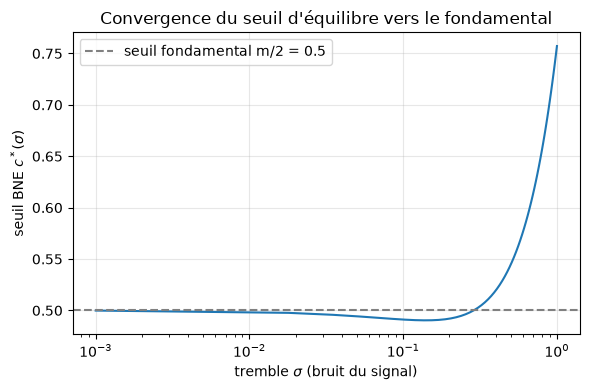

In [3]:
# --- la sélection : le seuil converge vers le fondamental m/2 quand sigma -> 0 ---
sigmas = np.linspace(0.001, 1.0, 60)
cstar = np.array([solve_cutoff(s) for s in sigmas])

plt.figure(figsize=(6, 4))
plt.plot(sigmas, cstar, "-")
plt.axhline(m / 2, color="grey", ls="--", label=f"seuil fondamental m/2 = {m/2}")
plt.xscale("log")
plt.xlabel("tremble $\\sigma$ (bruit du signal)")
plt.ylabel("seuil BNE $c^*(\\sigma)$")
plt.title("Convergence du seuil d'équilibre vers le fondamental")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** Quand le tremble s'amenuise, le seuil d'équilibre $c^*(\sigma)$ converge vers
$m/2$, le **seuil fondamental** du projet. À la limite, l'issue d'équilibre devient une
fonction de l'état réel $\theta$ — plus des croyances subjectives. C'est le théorème :
l'équilibre unique des jeux globaux **sélectionne** l'issue fondamentale.


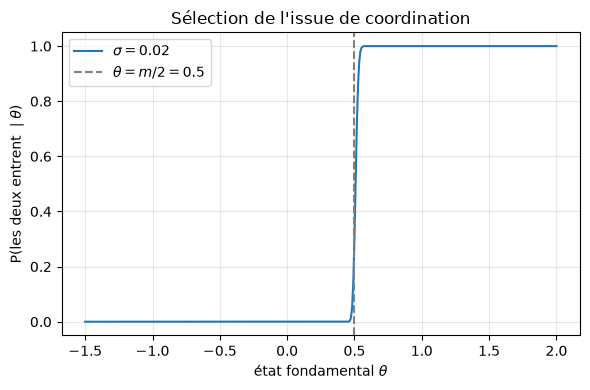

In [4]:
# --- l'issue sélectionnée : P(les deux entrent | theta) -> 1{theta > m/2} ---
sigma = 0.02
c = solve_cutoff(sigma)
thetas = np.linspace(-1.5, 2.0, 400)
p_both = np.array([(1 - norm.cdf((c - t) / sigma)) ** 2 for t in thetas])

plt.figure(figsize=(6, 4))
plt.plot(thetas, p_both, label=f"$\\sigma={sigma}$")
plt.axvline(m / 2, color="grey", ls="--", label=f"$\\theta = m/2 = {m/2}$")
plt.xlabel("état fondamental $\\theta$")
plt.ylabel("P(les deux entrent $\\mid \\theta)$")
plt.title("Sélection de l'issue de coordination")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** La probabilité de **coordonner sur l'entrée** passe de 0 à 1, franchement, au
seuil fondamental $m/2$. Le tremble $\to 0$ **sélectionne** l'issue efficace — coordonner
quand le projet vaut vraiment le coup — là où le jeu sans tremble laissait plusieurs issues
stables. La sélection est **lisible dans l'état**, pas dans les croyances.


In [5]:
# --- unicité : l'indifférence est strictement croissante -> un seul seuil BNE ---
sigma = 0.1
cs = np.linspace(-3, 3, 7)
Hvals = [indifference(cc, sigma) for cc in cs]
print("c   :", [f"{x:.1f}" for x in cs])
print("H(c):", [f"{h:+.3f}" for h in Hvals])
print("-> un seul changement de signe : l'équilibre de Nash bayésien est UNIQUE.")


c   : ['-3.0', '-2.0', '-1.0', '0.0', '1.0', '2.0', '3.0']
H(c): ['-3.554', '-2.536', '-1.518', '-0.500', '+0.518', '+1.536', '+2.554']
-> un seul changement de signe : l'équilibre de Nash bayésien est UNIQUE.


**Lecture.** $H(c)$ — le gain d'entrer au seuil — est **strictement croissante** : un seul
changement de signe, donc un **seul** seuil d'équilibre. C'est ce qui fait d'un jeu global un
outil de *sélection* : là où le jeu de base a plusieurs équilibres, le tremble n'en garde
**qu'un**.


## 3. Exercices


### Exercice 1 — le seuil d'équilibre

Reproduire la résolution de l'équilibre : pour un tremble donné, retourner le seuil BNE
$c^*(\sigma)$.


In [6]:
def seuil_bayesien(sigma):
    """Retourner le seuil d'équilibre c*(sigma).

    # TODO etudiant : appeler la bonne fonction du carnet ci-dessus.
    """
    return None  # TODO etudiant

# Indice : la résolution de l'indifférence est déjà écrite plus haut —
# réutilisez-la plutôt que de la réécrire.
print("Exercice à compléter :", seuil_bayesien(0.1))


Exercice à compléter : None


### Exercice 2 — la probabilité de coordination

Écrire la fonction qui, **donné** un état fondamental $\theta$, un seuil $c$ et un tremble
$\sigma$, retourne $P(\text{les deux entrent} \mid \theta)$.


In [7]:
def prob_coordonner(theta, c, sigma):
    """P(les deux entrent | theta), sachant que chacun entre si son signal >= c.

    # TODO etudiant : chaque signal x = theta + eps, avec eps ~ N(0, sigma^2).
    """
    return None  # TODO etudiant

# Indice : il faut la probabilité qu'UN signal dépasse c, puis le fait que les
# deux signaux (indépendants) le dépassent.
print("Exercice à compléter :", prob_coordonner(1.0, 0.5, 0.1))


Exercice à compléter : None


### Exercice 3 — l'effet d'un a priori décalé

Si l'état commun suit $\theta \sim \mathcal{N}(\mu_0, 1)$ au lieu de $\mathcal{N}(0,1)$,
comment bouge le seuil fondamental sélectionné ?


In [8]:
def seuil_fondamental(mu0):
    """Seuil fondamental sélectionné quand theta ~ N(mu0, 1).

    # TODO etudiant : exprimer le seuil en fonction de mu0 et de m.
    """
    return None  # TODO etudiant

# Indice : l'état moyen décale tout le jeu — de combien bouge le point
# d'indifférence quand la moyenne de l'état change ?
print("Exercice à compléter :", seuil_fondamental(0.5))


Exercice à compléter : None


## 4. Ce que la sélection par jeu global fait que l'induction en avant ne fait pas

[10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** en lisant une *action
observée* dans un *arbre* : renoncer à une option extérieure est un signal sur les
intentions. La sélection par **jeu global** n'a ni arbre ni action observée : elle naît de la
*structure des croyances* sur un état commun. Deux instruments de sélection, deux logiques —
l'un temporelle (forme extensive), l'autre informationnelle (forme normale). Le jeu global est
l'outil quand la coordination est **simultanée** et que l'indétermination vient de
l'information, pas de l'ordre des coups.
